**Recommended Resources for Further Exploration**

- PubChem - Molecular structures, properties, and bioassay data

https://pubchem.ncbi.nlm.nih.gov

- ChEMBL - Curated bioactivity data for drug discovery

https://ebi.ac.uk/chembl

- MoleculeNet / DeepChem - Benchmark datasets and tools for molecular machine learning

https://moleculenet.org

- Materials Project - Computational materials data and DFT-based properties

https://materialsproject.org

- OQMD - Open Quantum Materials Database, including formation energies and related materials data

https://oqmd.org

- ChEBI - Chemical Entities of Biological Interest

https://ebi.ac.uk/chebi

- Molecular Symmetry - An interactive resource for exploring molecular symmetry

https://symotter.org/

**1. Install conda (Google Colab)**

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:15
🔁 Restarting kernel...


In [ ]:
!mamba install -q -c conda-forge rdkit py3dmol

warning  libmamba [cffi-2.1.1-py313ha52865f_3] The following files were already present in the environment:
    - bin/cffi-gen-src
warning  libmamba [numpy-2.5.4-py313hb5f73ae_0] The following files were already present in the environment:
    - bin/f2py
    - bin/numpy-config
warning  libmamba [pygments-2.21.0-pyhcf101f3_0] The following files were already present in the environment:
    - bin/pygmentize
warning  libmamba [fonttools-4.66.1-py313h6cd9899_0] The following files were already present in the environment:
    - bin/fonttools
    - bin/pyftmerge
    - bin/pyftsubset
    - bin/ttx
    - share/man/man1/ttx.1
warning  libmamba [ipython-9.17.1-pyh53cf698_0] The following files were already present in the environment:
    - bin/ipython
    - bin/ipython3


**2. Import Libraries**

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
import py3Dmol

**3. Define SMILES**

In [ ]:
molecules = {
"Water": "O",
"Ethanol": "CCO",
"Benzene": "c1ccccc1"
}

https://pubchem.ncbi.nlm.nih.gov/#query=Na2SO4

https://www.moldraw.com/tools/free-chem-tools/smiles-to-molecular-formula.html

https://www.sigmaaldrich.com/BE/en/product/aldrich/440167?msockid=2fbe6eaff0496de71d9b790cf1cb6ccb

**4. Draw 2D Structures (RDKit)**

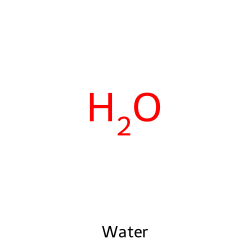

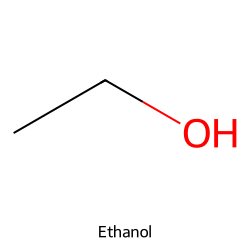

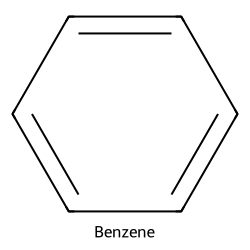

In [ ]:
for name, smiles in molecules.items():
  mol = Chem.MolFromSmiles(smiles)
  display(Draw.MolToImage(mol, size=(250,250), legend=name))

**5. Generate 3D Coordinates**

In [ ]:
# mol3d = Chem.AddHs(Chem.MolFromSmiles("[O-]S(=O)(=O)[O-].[Na+].[Na+]"))
# AllChem.EmbedMolecule(mol3d)
# AllChem.MMFFOptimizeMolecule(mol3d)
# molblock = Chem.MolToMolBlock(mol3d)

In [ ]:
mol3d = Chem.AddHs(Chem.MolFromSmiles("CCO"))
AllChem.EmbedMolecule(mol3d)
AllChem.MMFFOptimizeMolecule(mol3d)
molblock = Chem.MolToMolBlock(mol3d)

**6. Visualize in 3D (py3Dmol)**

In [ ]:
view = py3Dmol.view(width=500,height=400)
view.addModel(molblock,'mol')
view.setStyle({'stick':{}})
view.setBackgroundColor('white')
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**7. Function for Any SMILES**

In [ ]:
from rdkit.Chem import rdMolDescriptors

def show_molecule(smiles):
  # Get Mol object
  mol = Chem.MolFromSmiles(smiles)

  # Calculate Molecular Formula to use as a name
  formula = rdMolDescriptors.CalcMolFormula(mol)
  print(f"Molecule: {formula} (SMILES: {smiles})")

  # 2D visualization with legend
  display(Draw.MolToImage(mol, size=(250,250), legend=formula))

  # 3D visualization
  mol_3d = Chem.AddHs(mol)
  AllChem.EmbedMolecule(mol_3d)
  AllChem.MMFFOptimizeMolecule(mol_3d)
  mb = Chem.MolToMolBlock(mol_3d)

  view = py3Dmol.view(width=500, height=400)
  view.addModel(mb, 'mol')
  #view.setStyle({'stick':{}})
  # view.setStyle({'stick':{}})
  #view.setStyle({'sphere':{}})
  #view.setStyle({'line':{}})
  #view.setStyle({'cartoon':{}})
  view.setStyle({'stick': {}, 'sphere': {'scale': 0.3}})
  view.zoomTo()
  return view.show()

Molecule: C6H6 (SMILES: c1ccccc1)


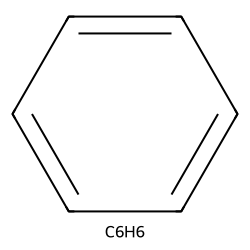

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("c1ccccc1") # Benzene

Molecule: C2H6O (SMILES: CCO)


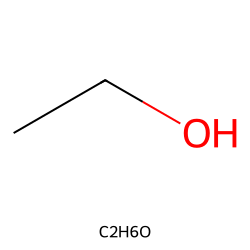

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("CCO") # Ethanol

Molecule: C2H4O2 (SMILES: CC(=O)O)


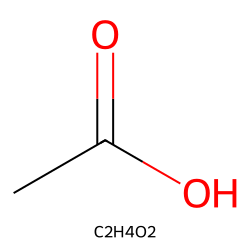

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("CC(=O)O") # Acetic acid

Molecule: C8H10N4O2 (SMILES: Cn1cnc2n(C)c(=O)n(C)c(=O)c12)


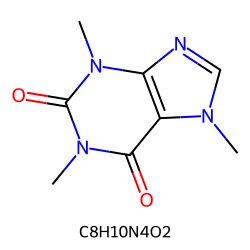

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("Cn1cnc2n(C)c(=O)n(C)c(=O)c12") # Caffeine

Molecule: C8H11NO2 (SMILES: C1=CC(=C(C=C1CCN)O)O)


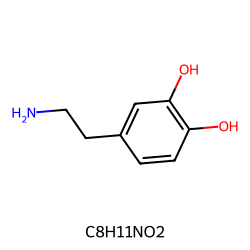

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("C1=CC(=C(C=C1CCN)O)O") # dopamine

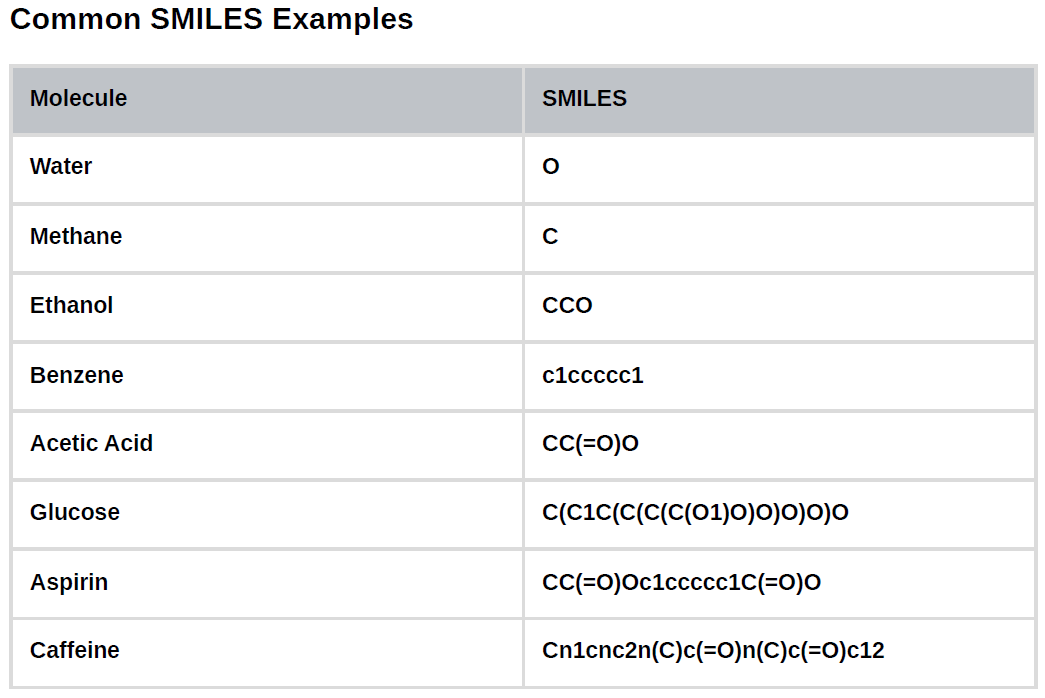

In [ ]:
# Example of the 'sphere' (space-filling) style
smiles = "Cn1cnc2n(C)c(=O)n(C)c(=O)c12" # Caffeine
mol = Chem.MolFromSmiles(smiles)
mol_3d = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol_3d)
AllChem.MMFFOptimizeMolecule(mol_3d)
mb = Chem.MolToMolBlock(mol_3d)

view = py3Dmol.view(width=500, height=400)
view.addModel(mb, 'mol')
# Using the cool 'sphere' style
view.setStyle({'sphere': {'scale': 0.5}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Example of the beautiful 'Ball and Stick' (Esfera e Bastão) style
smiles = "Cn1cnc2n(C)c(=O)n(C)c(=O)c12" # Caffeine
mol = Chem.MolFromSmiles(smiles)
mol_3d = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol_3d)
AllChem.MMFFOptimizeMolecule(mol_3d)
mb = Chem.MolToMolBlock(mol_3d)

view = py3Dmol.view(width=500, height=400)
view.addModel(mb, 'mol')

# Combining stick and scaled sphere for the perfect ball-and-stick look
view.setStyle({'stick': {}, 'sphere': {'scale': 0.3}})

view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Molecule: C54H105CeO6 (SMILES: CCCCCCCCCCCCCCCCCC(=O)[O-].CCCCCCCCCCCCCCCCCC(=O)[O-].CCCCCCCCCCCCCCCCCC(=O)[O-].[Ce+3])


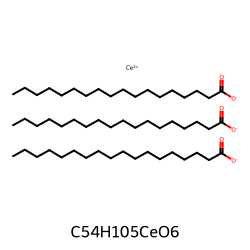

[11:56:17] UFFTYPER: Unrecognized charge state for atom: 0
[11:56:17] UFFTYPER: Unrecognized atom type: Ce+3 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("CCCCCCCCCCCCCCCCCC(=O)[O-].CCCCCCCCCCCCCCCCCC(=O)[O-].CCCCCCCCCCCCCCCCCC(=O)[O-].[Ce+3]") # "Cerium stearate"

Molecule: C9H7NO (SMILES: C1=CC2=C(C(=C1)O)N=CC=C2)


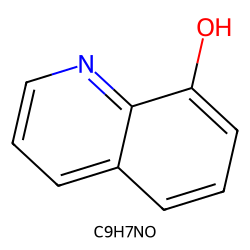

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("C1=CC2=C(C(=C1)O)N=CC=C2") # 8-HYDROXYQUINOLINE

Molecule: CrO4Zn (SMILES: [O-][Cr](=O)(=O)[O-].[Zn+2])


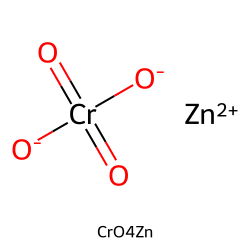

[11:57:08] UFFTYPER: Unrecognized atom type: Cr3+3 (1)
[11:57:08] UFFTYPER: Unrecognized charge state for atom: 0
[11:57:08] UFFTYPER: Unrecognized atom type: Zn+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("[O-][Cr](=O)(=O)[O-].[Zn+2]") # "ZINC CHROMATE"

Molecule: C9H20O5Si (SMILES: CO[Si](CCCOCC1CO1)(OC)OC)


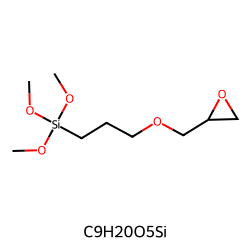

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:

show_molecule("CO[Si](CCCOCC1CO1)(OC)OC") #GPTMS

Molecule: C68H22 (SMILES: C1=CC2=CC3=CC4=C5C6=C3C7=C2C(=C1)C8=C9C7=C1C6=C2C3=C6C1=C1C9=C(C=CC1=CC6=CC1=C3C3=C6C(=C1)C=C1C=CC=C7C1=C6C1=C6C3=C2C5=C2C6=C3C(=CC2=C4)C=CC2=C3C1=C7C=C2)C=C8)


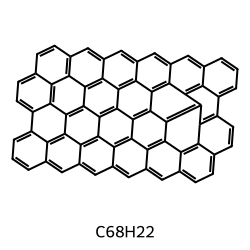

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("C1=CC2=CC3=CC4=C5C6=C3C7=C2C(=C1)C8=C9C7=C1C6=C2C3=C6C1=C1C9=C(C=CC1=CC6=CC1=C3C3=C6C(=C1)C=C1C=CC=C7C1=C6C1=C6C3=C2C5=C2C6=C3C(=CC2=C4)C=CC2=C3C1=C7C=C2)C=C8") # Graphene

Molecule: C8H20O4Si (SMILES: CCO[Si](OCC)(OCC)OCC)


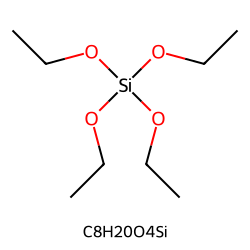

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
show_molecule("CCO[Si](OCC)(OCC)OCC") # TEOS

Molecule: H14O21Si7 (SMILES: O=[Si](O[Si](O)(O)O[Si](O)(O)O)O[Si](O[Si](O)(O)O)(O[Si](O)(O)O)O[Si](O)(O)O)


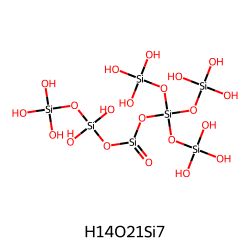

[12:17:04] UFFTYPER: Warning: hybridization set to SP3 for atom 1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Representation of a silica network/gel fragment generated from the condensation of hydrolyzed TEOS
# Contains multiple branched Si-O-Si bridges and some residual silanol (Si-OH) groups
show_molecule("O=[Si](O[Si](O)(O)O[Si](O)(O)O)O[Si](O[Si](O)(O)O)(O[Si](O)(O)O)O[Si](O)(O)O")

Molecule: H8O22Si9 (SMILES: O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O)O[Si]1(O)O[Si]6(O)O[Si](O)(O3)O[Si](O)(O4)O[Si](O)(O5)O6)


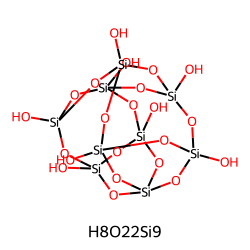

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Large, complex 3D silica network fragment (caged/highly branched POSS-like structure)
# Displays extensive 3D Si-O-Si interconnected linkages simulating a silica gel pore node
smiles_3d_network = "O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O)O[Si]1(O)O[Si]6(O)O[Si](O)(O3)O[Si](O)(O4)O[Si](O)(O5)O6"
show_molecule(smiles_3d_network)

Molecule: H12O33Si14 (SMILES: O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si](O)(O3)O[Si](O)(O4)O[Si]9(O)O[Si]8(O)O[Si](O)(O6)O[Si](O)(O7)O9)


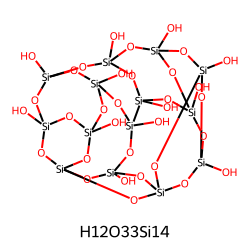

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Large polymeric silica gel fragment
# Constructed with multiple interconnected silsesquioxane rings to simulate an extended polymer network
large_silica_polymer = "O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si](O)(O3)O[Si](O)(O4)O[Si]9(O)O[Si]8(O)O[Si](O)(O6)O[Si](O)(O7)O9"
show_molecule(large_silica_polymer)

Molecule: H12O35Si15 (SMILES: O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si]9(O[Si](O)(O3)O[Si](O)(O4)O9)O[Si]1(O)O[Si]8(O)O[Si](O)(O6)O[Si](O)(O7)O1)


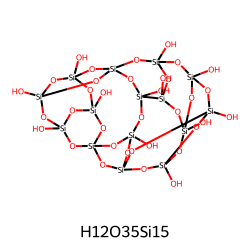

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Giant polymeric silica gel network node with highly extended 3D connections
extended_silica_network = "O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si]9(O[Si](O)(O3)O[Si](O)(O4)O9)O[Si]1(O)O[Si]8(O)O[Si](O)(O6)O[Si](O)(O7)O1"
show_molecule(extended_silica_network)

Molecule: H15O41Si20 (SMILES: O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si]9(O[Si](O)(O3)O[Si](O)(O4)9)O[Si]1(O)O[Si]8(O)O[Si]8(O[Si](O)(O6)O[Si](O)(O7)8)O[Si]2(O)O[Si]3(O)O[Si]1(O)O[Si]23)


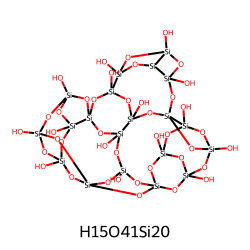

[12:20:24] UFFTYPER: Unrecognized charge state for atom: 60


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
# Giant highly-extended 3D silica gel polymer network
# Formed by several interconnected and fused silsesquioxane cage structures to simulate a continuous nanostructured gel
giant_silica_network = "O1[Si]2(O[Si]3(O)O[Si]4(O)O2)O[Si]5(O[Si]6(O)O[Si]7(O)O5)O[Si]1(O)O[Si]8(O)O[Si]9(O[Si](O)(O3)O[Si](O)(O4)9)O[Si]1(O)O[Si]8(O)O[Si]8(O[Si](O)(O6)O[Si](O)(O7)8)O[Si]2(O)O[Si]3(O)O[Si]1(O)O[Si]23"
show_molecule(giant_silica_network)